Rows, columns: (169, 12)
Training videos: 121 | Testing videos: 31

R2 score on test data: 0.59 (1.0 = perfect, 0 = useless)

Sample predictions:
 Real views  Predicted views
     935729           652785
      33425           216508
     596663           617115
     744985           425722
     136114           703760
     120148           215392
    3160432          2506038
   10278447          3492330

Feature importance:
Stayed to watch (%)                 0.408
days_old                            0.313
Thumbnail click-through rate (%)    0.150
Duration                            0.073
title_length                        0.051
hashtags                            0.005
dtype: float64

Predicted views for the new video: 961,753


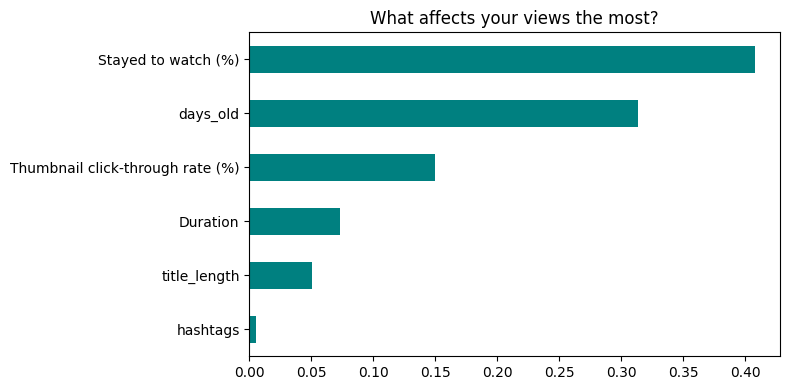

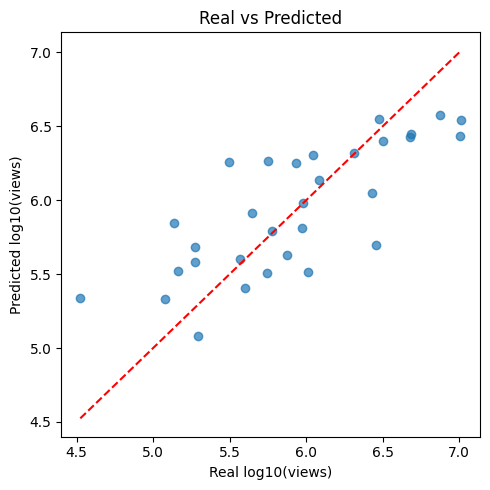

In [ ]:

#  BEGINNER ML MODEL: Predict YouTube video VIEWS

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score

#STEP 1: Load the data
df = pd.read_csv("Table data.csv")
print("Rows, columns:", df.shape)



#STEP 2: Clean the data 
df = df[df["Content"] != "Total"]          # remove the 'Total' summary row
df = df[df["Duration"] <= 180]             # keep only Shorts (3 min or less)


#STEP 3: Make new useful columns (feature engineering)
df["publish_date"] = pd.to_datetime(df["Video publish time"])
df["days_old"] = (pd.Timestamp.today() - df["publish_date"]).dt.days   # video age
df["hashtags"] = df["Video title"].fillna("").str.count("#")           # number of hashtags
df["title_length"] = df["Video title"].fillna("").str.len()            # title length


#STEP 4: Choose INPUTS (X) and OUTPUT (y) 
features = [
    "Duration",                          # video length in seconds
    "Stayed to watch (%)",               # % of people who didn't swipe away
    "Thumbnail click-through rate (%)",  # CTR
    "days_old",
    "hashtags",
    "title_length",
]
df = df.dropna(subset=features + ["Views"])   # remove rows with missing values

X = df[features]
# Views are HUGE and uneven (2 thousand to 30 million), so we use log10.
# This makes learning much easier for the model.
y = np.log10(df["Views"])


#STEP 5: Split into train (80%) and test (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("Training videos:", len(X_train), "| Testing videos:", len(X_test))

#STEP 6: Create and train the model
model = RandomForestRegressor(n_estimators=200, min_samples_leaf=3, random_state=42)
model.fit(X_train, y_train)

#STEP 7: Test the model
pred = model.predict(X_test)
print("\nR2 score on test data:", round(r2_score(y_test, pred), 2),
      "(1.0 = perfect, 0 = useless)")

# Show real vs predicted views for a few test videos
result = pd.DataFrame({
    "Real views": (10 ** y_test).round().astype(int),
    "Predicted views": (10 ** pred).round().astype(int),
})
print("\nSample predictions:")
print(result.head(8).to_string(index=False))

#STEP 8: What matters most?
importance = pd.Series(model.feature_importances_, index=features).sort_values()
print("\nFeature importance:")
print(importance.sort_values(ascending=False).round(3))

plt.figure(figsize=(8, 4))
importance.plot(kind="barh", color="teal")
plt.title("What affects your views the most?")
plt.tight_layout()
plt.savefig("feature_importance.png")

plt.figure(figsize=(5, 5))
plt.scatter(y_test, pred, alpha=0.7)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
plt.xlabel("Real log10(views)")
plt.ylabel("Predicted log10(views)")
plt.title("Real vs Predicted")
plt.tight_layout()
plt.savefig("real_vs_predicted.png")

#STEP 9: Predict for a NEW video
new_video = pd.DataFrame([{
    "Duration": 58,
    "Stayed to watch (%)": 78,
    "Thumbnail click-through rate (%)": 7,
    "days_old": 30,
    "hashtags": 4,
    "title_length": 80,
}])
guess = 10 ** model.predict(new_video)[0]
print(f"\nPredicted views for the new video: {guess:,.0f}")